# Football Expected Goals (xG) Model
Build my own xG model: the chance that a shot becomes a goal, from where and how it was taken.


**Data:** StatsBomb free open data (2018 World Cup matches) read from their public GitHub, no login. If the download fails a small synthetic shot sample is made.

**Models:** average goal rate (baseline), Logistic Regression, Gradient Boosting. Penalties are removed. At the end my model is compared with the xG that StatsBomb gives in the data.

In [1]:
!pip install -q pandas numpy scikit-learn matplotlib requests

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

base = "https://raw.githubusercontent.com/statsbomb/open-data/master/data/"
shots = []
try:
    matches = requests.get(base + "matches/43/3.json", timeout=30).json()
    print("matches in competition:", len(matches))
    for m in matches[:40]:
        events = requests.get(base + "events/" + str(m["match_id"]) + ".json", timeout=60).json()
        for e in events:
            if e["type"]["name"] == "Shot":
                s = e["shot"]
                shots.append({
                    "match_id": m["match_id"],
                    "x": e["location"][0],
                    "y": e["location"][1],
                    "goal": int(s["outcome"]["name"] == "Goal"),
                    "body_part": s["body_part"]["name"],
                    "shot_type": s["type"]["name"],
                    "first_time": int(s.get("first_time", False)),
                    "under_pressure": int(e.get("under_pressure", False)),
                    "sb_xg": s.get("statsbomb_xg", np.nan),
                })
    shots = pd.DataFrame(shots)
    print("real data loaded:", shots.shape)
except Exception as err:
    print("download failed, making synthetic shots instead:", err)
    n = 1500
    x = np.random.uniform(70, 119, n)
    y = np.random.uniform(15, 65, n)
    d = np.sqrt((120 - x) ** 2 + (40 - y) ** 2)
    p = np.clip(0.45 - 0.017 * d, 0.01, 0.6)
    shots = pd.DataFrame({"match_id": np.random.randint(1, 40, n), "x": x, "y": y, "goal": (np.random.rand(n) < p).astype(int),
                          "body_part": np.random.choice(["Right Foot", "Left Foot", "Head"], n, p=[0.5, 0.3, 0.2]),
                          "shot_type": np.random.choice(["Open Play", "Free Kick", "Corner"], n, p=[0.85, 0.08, 0.07]),
                          "first_time": np.random.randint(0, 2, n), "under_pressure": np.random.randint(0, 2, n), "sb_xg": p})

shots.head()

matches in competition: 64
real data loaded: (1050, 9)


,match_id,x,y,goal,body_part,shot_type,first_time,under_pressure,sb_xg
0,8650,91.0,51.0,0,Right Foot,Open Play,0,0,0.020461
1,8650,115.0,39.0,0,Right Foot,Open Play,1,0,0.274021
2,8650,106.0,31.0,0,Right Foot,Open Play,0,0,0.065900
3,8650,92.0,29.0,0,Right Foot,Open Play,0,0,0.022908
4,8650,109.0,46.0,0,Right Foot,Open Play,1,0,0.174216


In [3]:
shots = shots[shots["shot_type"] != "Penalty"].copy()
print("shots without penalties:", len(shots), " goals:", shots["goal"].sum(), " goal rate:", round(shots["goal"].mean(), 3))

shots["distance"] = np.sqrt((120 - shots["x"]) ** 2 + (40 - shots["y"]) ** 2)
dx = 120 - shots["x"]
dy = shots["y"] - 40
shots["angle"] = np.arctan2(7.32 * dx, dx ** 2 + dy ** 2 - (7.32 / 2) ** 2)
shots.loc[shots["angle"] < 0, "angle"] = shots["angle"] + np.pi
shots["is_header"] = (shots["body_part"] == "Head").astype(int)
shots["is_free_kick"] = (shots["shot_type"] == "Free Kick").astype(int)
shots["is_corner"] = (shots["shot_type"] == "Corner").astype(int)

shots[["distance", "angle", "goal"]].describe().round(3)

shots without penalties: 1011  goals: 82  goal rate: 0.081


,distance,angle,goal
count,1011.000,1011.000,1011.000
mean,19.516,0.404,0.081
std,8.903,0.280,0.273
min,1.414,0.047,0.000
25%,12.207,0.232,0.000
50%,19.000,0.302,0.000
75%,26.173,0.478,0.000
max,61.522,2.571,1.000


             count  sum   mean
dist_bucket                   
(0, 6]          34   14  0.412
(6, 10]        140   25  0.179
(10, 14]       144   12  0.083
(14, 18]       155   12  0.077
(18, 25]       247   12  0.049
(25, 60]       290    7  0.024


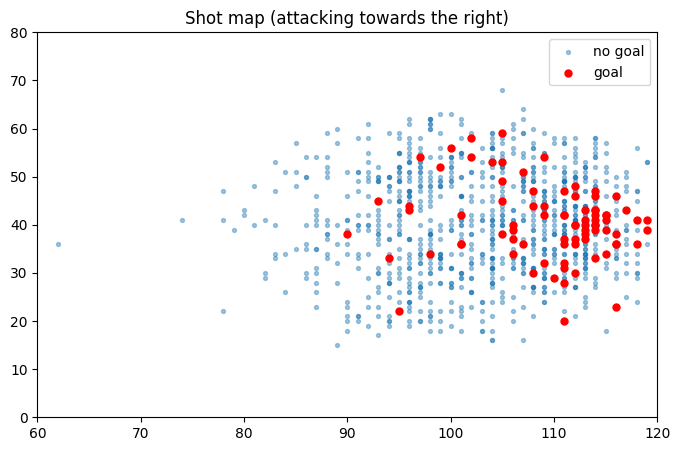

In [4]:
shots["dist_bucket"] = pd.cut(shots["distance"], bins=[0, 6, 10, 14, 18, 25, 60])
print(shots.groupby("dist_bucket", observed=True)["goal"].agg(["count", "sum", "mean"]).round(3))

plt.figure(figsize=(8, 5))
plt.scatter(shots[shots["goal"] == 0]["x"], shots[shots["goal"] == 0]["y"], s=8, alpha=0.4, label="no goal")
plt.scatter(shots[shots["goal"] == 1]["x"], shots[shots["goal"] == 1]["y"], s=25, color="red", label="goal")
plt.xlim(60, 120)
plt.ylim(0, 80)
plt.title("Shot map (attacking towards the right)")
plt.legend()
plt.show()

In [5]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

features = ["distance", "angle", "is_header", "is_free_kick", "is_corner", "first_time", "under_pressure"]
X = shots[features]
y = shots["goal"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=shots["match_id"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("train shots:", len(X_train), "test shots:", len(X_test), " test goals:", y_test.sum())

base_rate = y_train.mean()
base_prob = np.full(len(y_test), base_rate)
print("Baseline (same chance for every shot) log loss:", round(log_loss(y_test, base_prob), 4), " Brier:", round(brier_score_loss(y_test, base_prob), 4))

train shots: 760 test shots: 251  test goals: 25
Baseline (same chance for every shot) log loss: 0.3282  Brier: 0.0903


In [6]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(X_train, y_train)
lr_prob = lr.predict_proba(X_test)[:, 1]
print("Logistic Regression  AUC:", round(roc_auc_score(y_test, lr_prob), 4), " log loss:", round(log_loss(y_test, lr_prob), 4), " Brier:", round(brier_score_loss(y_test, lr_prob), 4))

gb = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.05, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
gb_prob = gb.predict_proba(X_test)[:, 1]
print("Gradient Boosting    AUC:", round(roc_auc_score(y_test, gb_prob), 4), " log loss:", round(log_loss(y_test, gb_prob), 4), " Brier:", round(brier_score_loss(y_test, gb_prob), 4))

sb_test = shots.iloc[test_idx]["sb_xg"]
if sb_test.notna().all():
    print("StatsBomb own xG     AUC:", round(roc_auc_score(y_test, sb_test), 4), " log loss:", round(log_loss(y_test, sb_test), 4), " Brier:", round(brier_score_loss(y_test, sb_test), 4))

Logistic Regression  AUC: 0.7704  log loss: 0.2778  Brier: 0.0785
Gradient Boosting    AUC: 0.7062  log loss: 0.2959  Brier: 0.0796
StatsBomb own xG     AUC: 0.8207  log loss: 0.2514  Brier: 0.0693


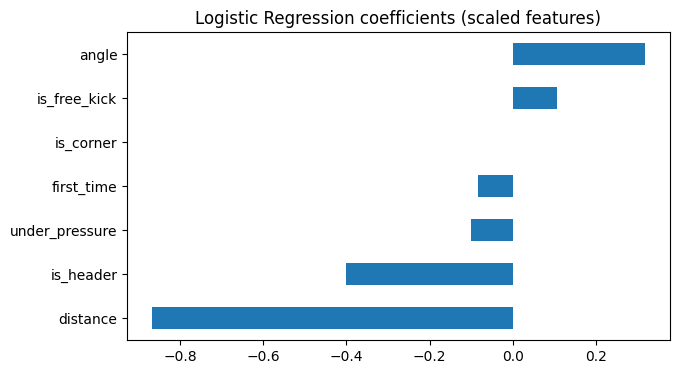

distance         -0.868
is_header        -0.402
under_pressure   -0.101
first_time       -0.084
is_corner         0.000
is_free_kick      0.107
angle             0.318
dtype: float64

total goals in test set: 25
total xG from my model: 18.2


In [7]:
coef = pd.Series(lr[-1].coef_[0], index=features).sort_values()
coef.plot(kind="barh", figsize=(7, 4), title="Logistic Regression coefficients (scaled features)")
plt.show()
print(coef.round(3))

print()
print("total goals in test set:", y_test.sum())
print("total xG from my model:", round(lr_prob.sum(), 1))

             shots  avg_xg  goal_rate
bucket                               
(0.0, 0.05]    125   0.030      0.032
(0.05, 0.1]     76   0.073      0.105
(0.1, 0.2]      36   0.137      0.139
(0.2, 0.4]      13   0.273      0.538
(0.4, 1.0]       1   0.427      1.000


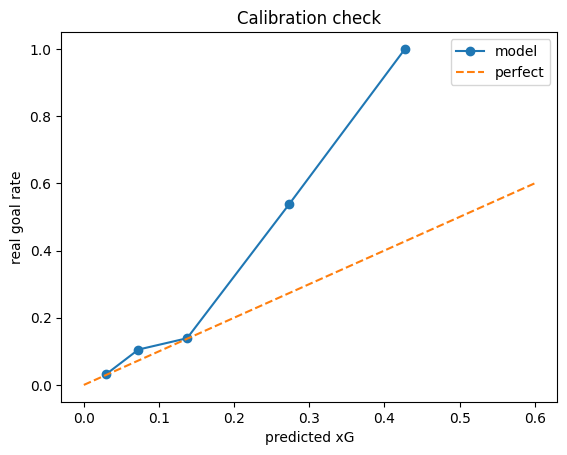


Example shots from my model:
   distance  angle  is_header  is_free_kick  is_corner  first_time  \
0         6    0.9          0             0          0           0   
1        12    0.5          0             0          0           0   
2        25    0.2          0             0          0           0   
3        11    0.6          1             0          0           0   

   under_pressure     xG  
0               0  0.317  
1               0  0.143  
2               0  0.033  
3               0  0.069  


In [8]:
test_data = shots.iloc[test_idx].copy()
test_data["my_xg"] = lr_prob
test_data["bucket"] = pd.cut(test_data["my_xg"], bins=[0, 0.05, 0.1, 0.2, 0.4, 1.0])
check = test_data.groupby("bucket", observed=True).agg(shots=("goal", "count"), avg_xg=("my_xg", "mean"), goal_rate=("goal", "mean"))
print(check.round(3))

plt.plot(check["avg_xg"], check["goal_rate"], marker="o", label="model")
plt.plot([0, 0.6], [0, 0.6], linestyle="--", label="perfect")
plt.xlabel("predicted xG")
plt.ylabel("real goal rate")
plt.title("Calibration check")
plt.legend()
plt.show()

print()
print("Example shots from my model:")
example = pd.DataFrame({"distance": [6, 12, 25, 11], "angle": [0.9, 0.5, 0.2, 0.6], "is_header": [0, 0, 0, 1],
                        "is_free_kick": [0, 0, 0, 0], "is_corner": [0, 0, 0, 0], "first_time": [0, 0, 0, 0], "under_pressure": [0, 0, 0, 0]})
example["xG"] = lr.predict_proba(example[features])[:, 1].round(3)
print(example)

In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)